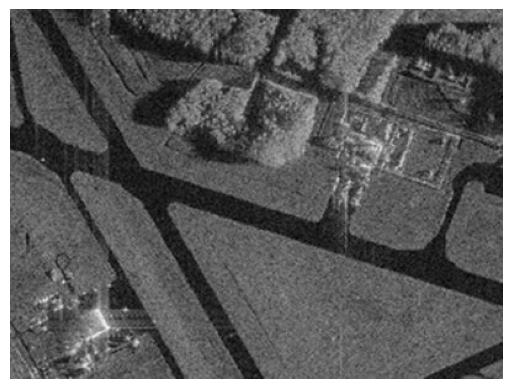

In [1]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

image = cv2.imread('sar_1.jpg')
image_gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
plt.imshow(image_gray, cmap='gray')
plt.axis('off')
plt.show()

r = 1  T = 10  area = 16072
r = 2  T = 25  area = 21417
r = 4  T = 25  area = 21426


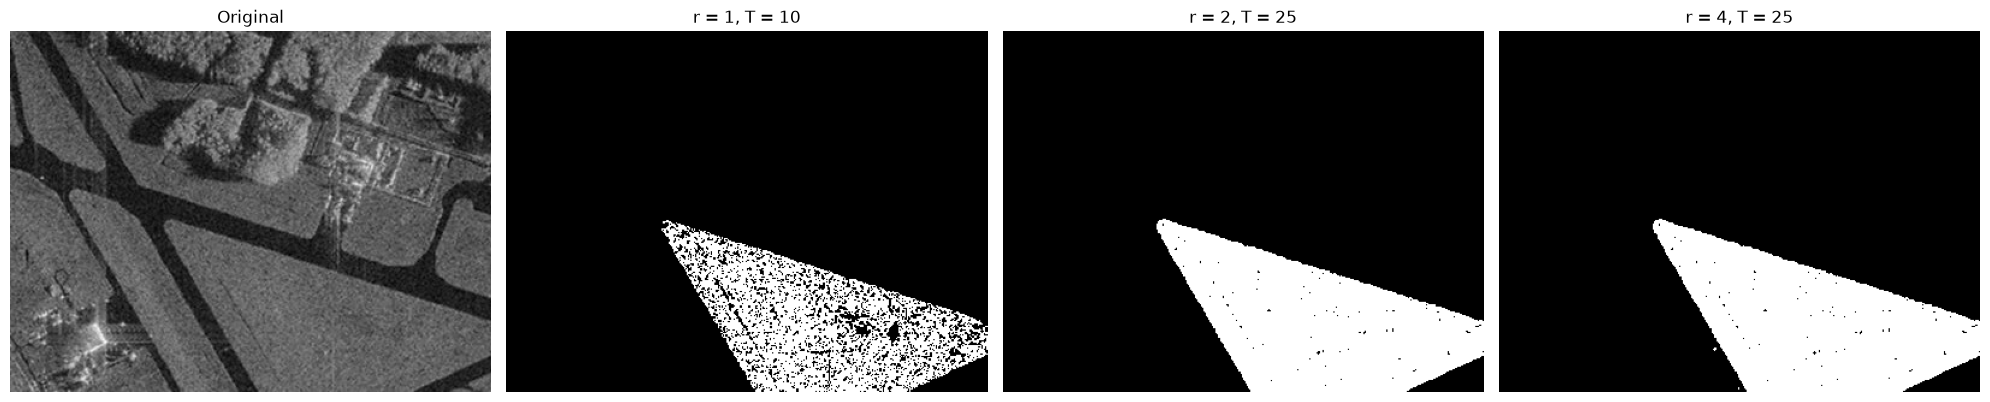

In [2]:
# 1. Подбор параметров алгоритма разрастания регионов для газона

def homo_average(img, mask, point, T):
    av = img[mask > 0].mean()
    return abs(av - img[point]) <= T

def region_growing(image, seed, homo_fun, r, T):
    mask = np.zeros(image.shape, np.uint8)
    mask[seed] = 1
    kernel = np.ones((2*r + 1, 2*r + 1), np.uint8)

    while True:
        dilated = cv2.dilate(mask, kernel)
        candidates = np.argwhere((dilated > 0) & (mask == 0))
        if len(candidates) == 0:
            break

        local = np.zeros(image.shape, np.uint8)
        for i, j in candidates:
            if homo_fun(image, mask, (i, j), T):
                local[i, j] = 1

        if np.count_nonzero(local) == 0:
            break
        mask += local

    return mask * 255

seed = (250, 250)
params = [(1, 10), (2, 25), (4, 25)]
results = []

for r, T in params:
    m = region_growing(image_gray, seed, homo_average, r, T)
    results.append(m)
    print('r =', r, ' T =', T, ' area =', np.count_nonzero(m))

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
ax[0].imshow(image_gray, cmap='gray'); ax[0].set_title('Original')
for i, (r, T) in enumerate(params, 1):
    ax[i].imshow(results[i-1], cmap='gray')
    ax[i].set_title('r = ' + str(r) + ', T = ' + str(T))
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

Area average: 21417
Area median : 21421
IoU: 0.9998


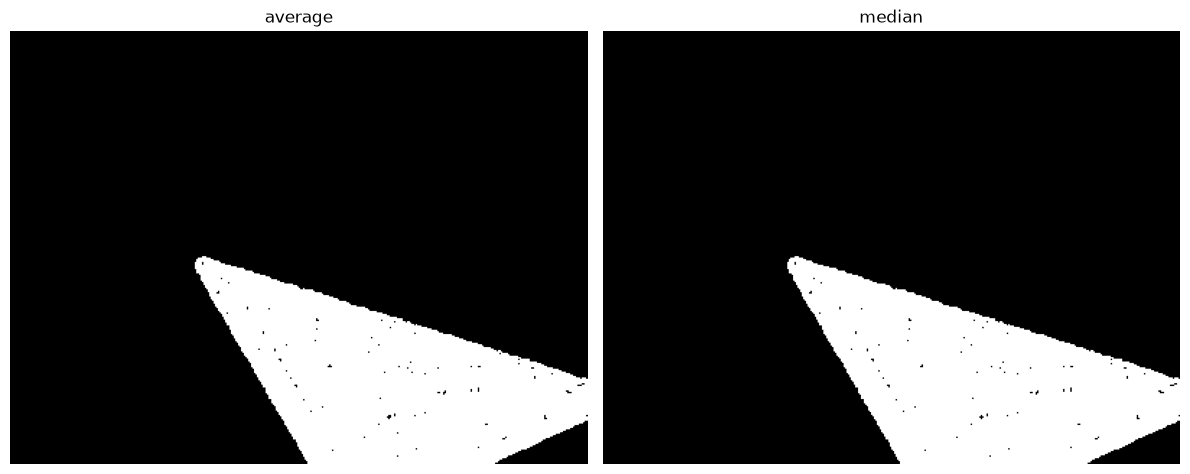

In [3]:
# 2. Другой критерий однородности — медиана

def homo_median(img, mask, point, T):
    med = np.median(img[mask > 0])
    return abs(med - img[point]) <= T

mask_avg = region_growing(image_gray, seed, homo_average, 2, 25)
mask_med = region_growing(image_gray, seed, homo_median, 2, 25)

inter = np.count_nonzero((mask_avg > 0) & (mask_med > 0))
union = np.count_nonzero((mask_avg > 0) | (mask_med > 0))
iou = inter / union if union else 0

print('Area average:', np.count_nonzero(mask_avg))
print('Area median :', np.count_nonzero(mask_med))
print('IoU:', round(iou, 4))

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(mask_avg, cmap='gray'); ax[0].set_title('average'); ax[0].axis('off')
ax[1].imshow(mask_med, cmap='gray'); ax[1].set_title('median');  ax[1].axis('off')
plt.tight_layout(); plt.show()

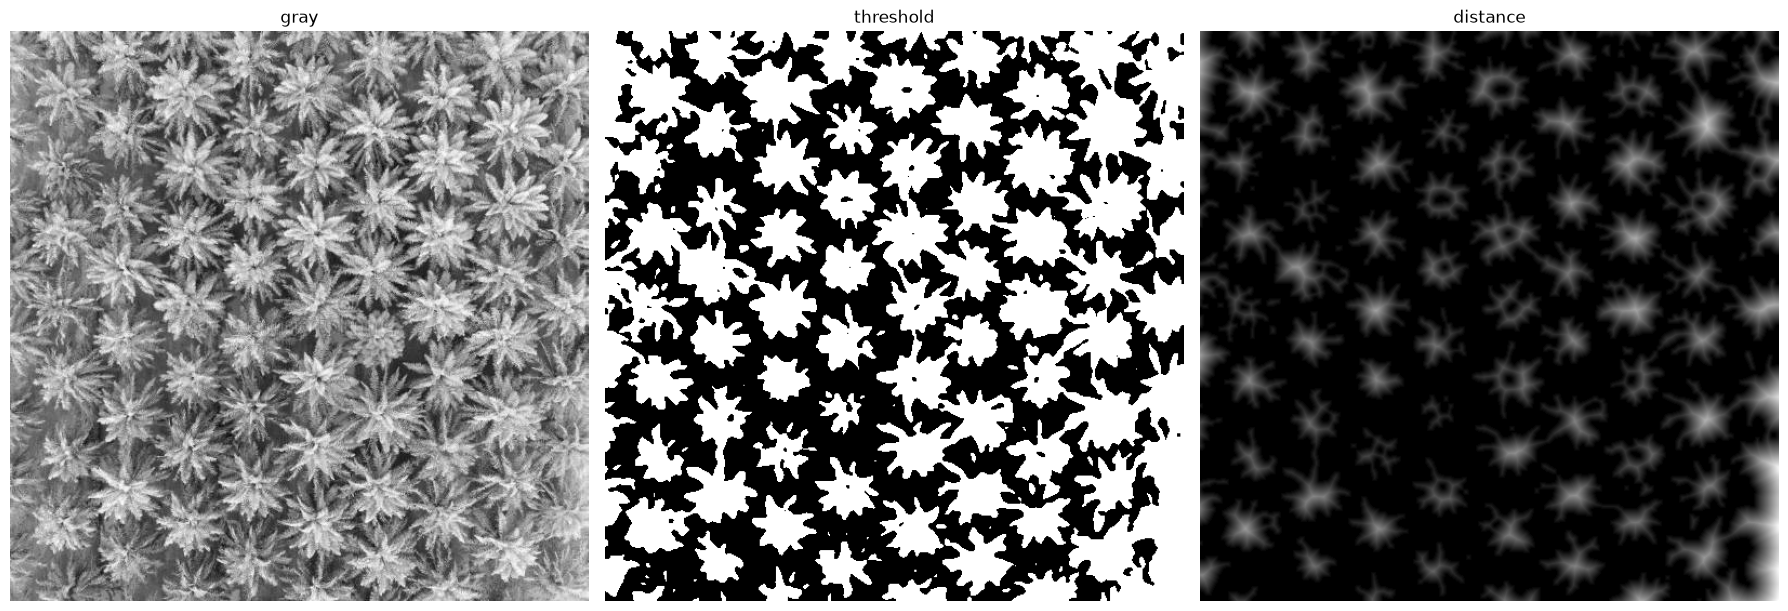

In [4]:
# 3. Watershed + Distance Transform — подсчёт пальм

palm = cv2.imread('palm_1.JPG')
palm_gray = cv2.cvtColor(palm, cv2.COLOR_BGR2GRAY)

blur = cv2.GaussianBlur(palm_gray, (11, 11), 0)
_, thresh = cv2.threshold(blur, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

kernel = np.ones((3, 3), np.uint8)
opening = cv2.morphologyEx(thresh, cv2.MORPH_OPEN, kernel, iterations=2)
sure_bg = cv2.dilate(opening, kernel, iterations=3)
dist = cv2.distanceTransform(opening, cv2.DIST_L2, 5)

fig, ax = plt.subplots(1, 3, figsize=(18, 6))
ax[0].imshow(palm_gray, cmap='gray'); ax[0].set_title('gray');    ax[0].axis('off')
ax[1].imshow(thresh, cmap='gray');    ax[1].set_title('threshold'); ax[1].axis('off')
ax[2].imshow(dist, cmap='gray');      ax[2].set_title('distance');  ax[2].axis('off')
plt.tight_layout(); plt.show()

Palm count: 97


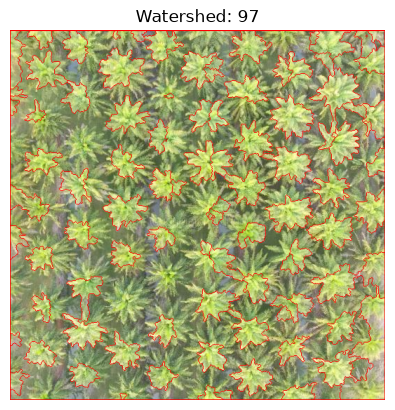

In [5]:
# 3. Watershed — маркеры и подсчёт

_, sure_fg = cv2.threshold(dist, 0.3 * dist.max(), 255, cv2.THRESH_BINARY)
sure_fg = sure_fg.astype(np.uint8)

unknown = cv2.subtract(sure_bg, sure_fg)
_, markers = cv2.connectedComponents(sure_fg)
markers += 1
markers[unknown == 255] = 0
markers = cv2.watershed(palm, markers)

count = len(np.unique(markers[markers > 1]))
print('Palm count:', count)

result = cv2.cvtColor(palm, cv2.COLOR_BGR2RGB).copy()
result[markers == -1] = [255, 0, 0]

plt.imshow(result)
plt.title('Watershed: ' + str(count))
plt.axis('off')
plt.show()